## 1 The CMB angular power spectrum

1. La cantidad equivalente sa $C_\ell$ es el espectro de potencia $P_\ell$
2. La equivalencia de $\delta_{\vec{k}}$ son los coeficientes de la expansión de armónicos $a_{\ell m}$.
3. No, el espectro de potencias $C_\ell$ solo determina un cierto aspecto de los cmpos gaussianos que representan el CMB, así que dos distintas realizaciones con el mismo $C_\ell$ no van a ser los mismos.
4. Van a conservar el promedio, las dimensiones de la caja en espacio de configuraciones y las fases.
5. Yo esperaría que representen lo mismo que las $k$, grandes $\ell$ deben representar a la estructura en pequeña escala en espacio real.

## 2 Generate a theoretical CMB power spectrum

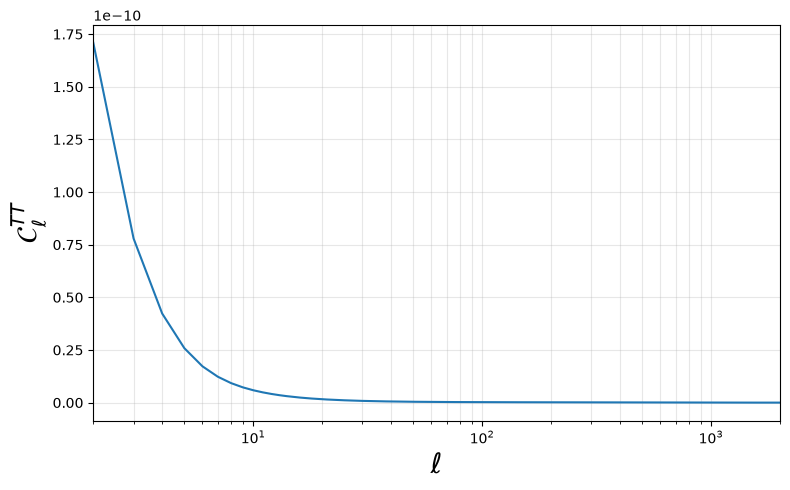

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import camb

h2 = 0.70 ** 2

pars = camb.set_params(H0=70, ombh2=0.25*h2, omch2=0.05*h2)
results = camb.get_results(pars)

Dl = results.get_total_cls(lmax=2000)[:, 0]
Cl = results.get_total_cls(lmax=2000, raw_cl=True)[:, 0]
ell = np.arange(Cl.shape[0])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ell[2:], Cl[2:], lw=1.5)
ax.set_xscale('log')
ax.set_xlim(2, ell[-1])
ax.set_xlabel(r'$\ell$', fontsize=20)
ax.set_ylabel(r'$\mathcal{C}_\ell^{TT}$', fontsize=20)
ax.grid(alpha=0.3, which='both')
fig.tight_layout()
plt.show()

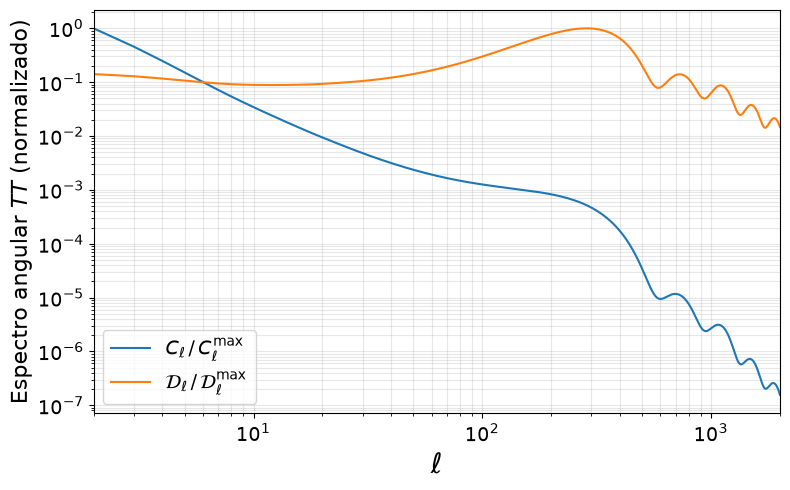

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(ell[2:], Cl[2:] / Cl[2:].max(), lw=1.5, label=r'$C_\ell \,/\, C_\ell^{\max}$')
ax.loglog(ell[2:], Dl[2:] / Dl[2:].max(), lw=1.5, label=r'$\mathcal{D}_\ell \,/\, \mathcal{D}_\ell^{\max}$')
ax.set_xlim(2, ell[-1])
ax.set_xlabel(r'$\ell$', fontsize=20)
ax.set_ylabel(r'Espectro angular $TT$ (normalizado)', fontsize=16)
ax.tick_params(labelsize=14)
ax.legend(fontsize=14)
ax.grid(alpha=0.3, which='both')
fig.tight_layout()
plt.show()

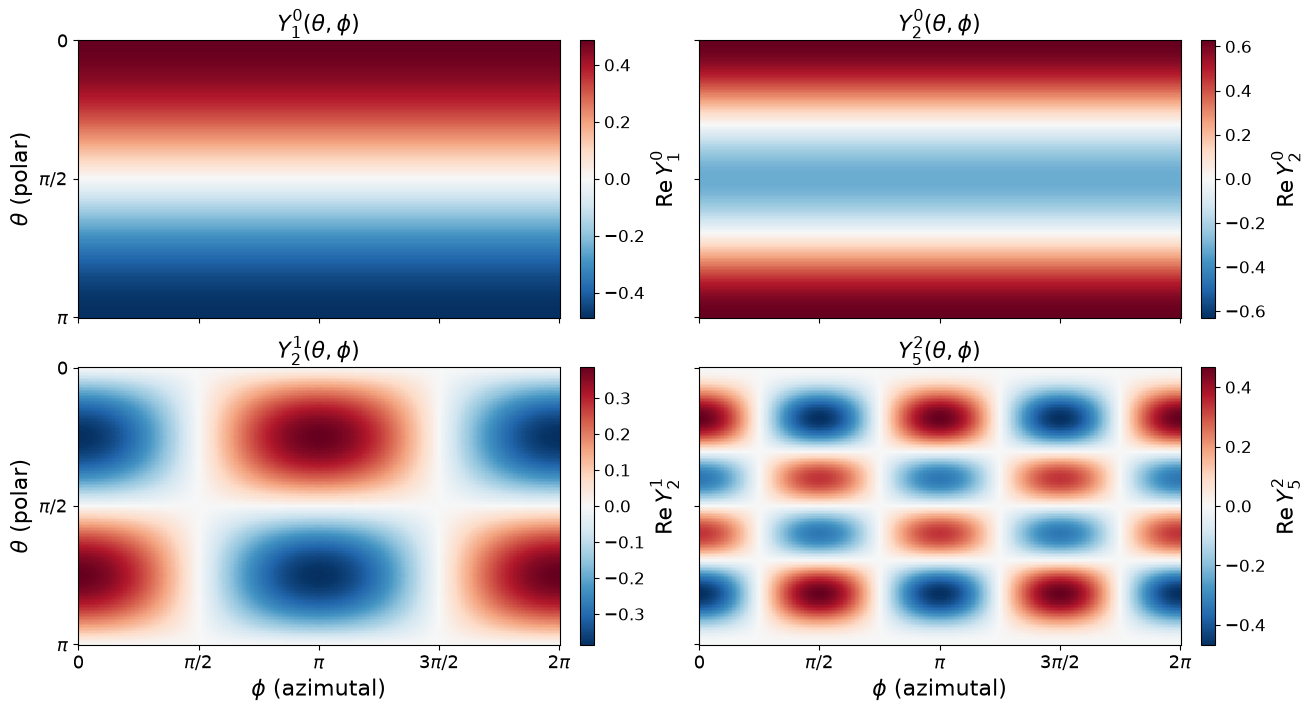

In [38]:
from scipy.special import sph_harm_y

theta = np.linspace(0, np.pi, 181)
phi   = np.linspace(0, 2*np.pi, 361)
AZ, POL = np.meshgrid(phi, theta)

modos = [(1, 0), (2, 0), (2, 1), (5, 2)]
Ys = {(l, m): sph_harm_y(l, m, POL, AZ).real for l, m in modos}

fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos):
    Y = Ys[(l, m)]
    vmax = np.abs(Y).max()                     # escala simétrica: blanco = 0
    im = ax.pcolormesh(AZ, POL, Y, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
    cb = fig.colorbar(im, ax=ax, pad=0.02)
    cb.set_label(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=16)
    cb.ax.tick_params(labelsize=12)
    ax.set_title(rf'$Y_{{{l}}}^{{{m}}}(\theta,\phi)$', fontsize=16)
    ax.set_xticks(np.linspace(0, 2*np.pi, 5), ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'], fontsize=13)
    ax.set_yticks(np.linspace(0, np.pi, 3), ['0', r'$\pi/2$', r'$\pi$'], fontsize=13)
axs[0, 0].invert_yaxis()                       # polo norte (θ=0) arriba (sharey: aplica a todos)
for ax in axs[1]: ax.set_xlabel(r'$\phi$ (azimutal)', fontsize=16)
for ax in axs[:, 0]: ax.set_ylabel(r'$\theta$ (polar)', fontsize=16)
plt.show()

In [54]:
sph_harm_y(1, 0, POL, AZ).imag

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(181, 361))

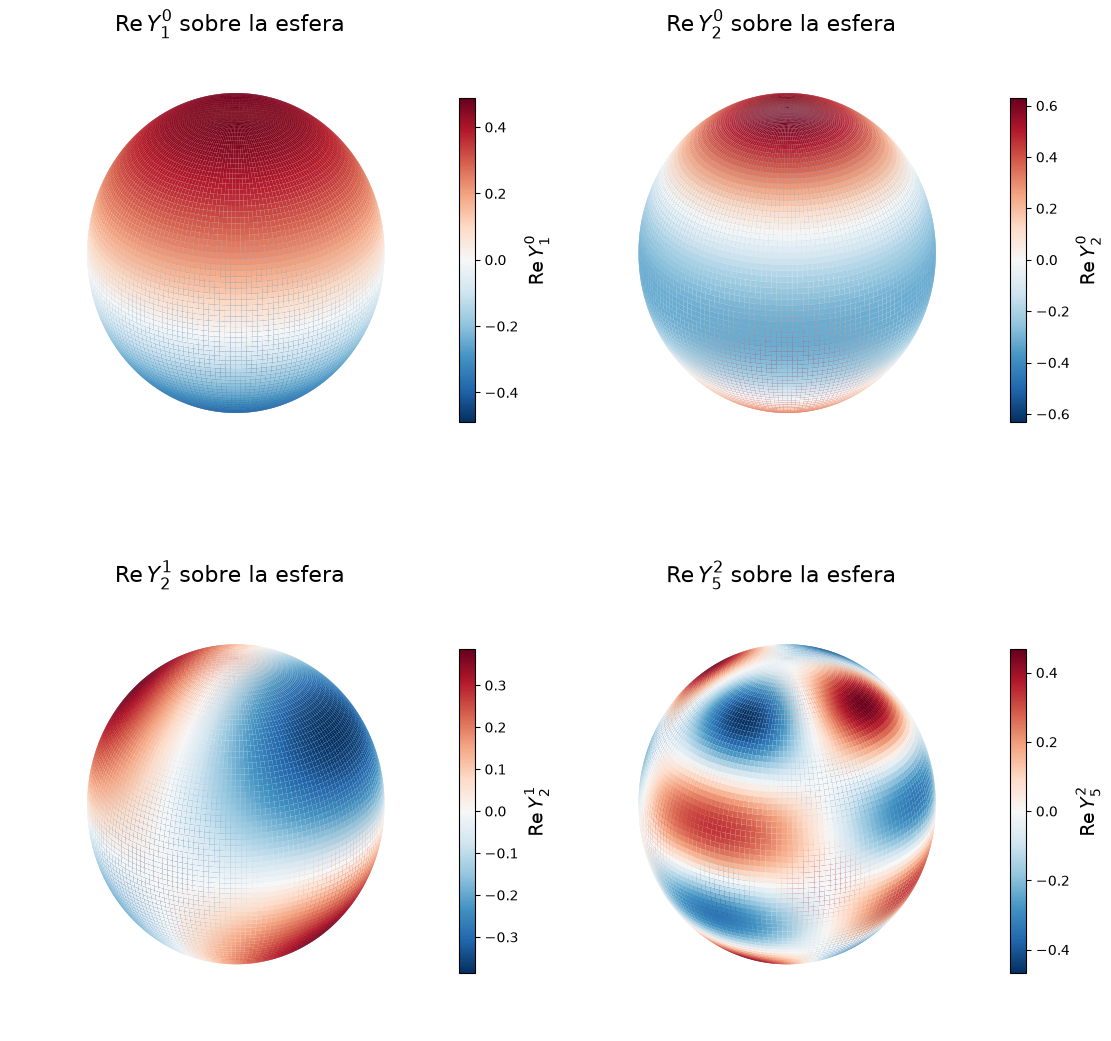

In [ ]:
X = np.sin(POL) * np.cos(AZ)
Yc = np.sin(POL) * np.sin(AZ)
Z = np.cos(POL)

fig, axs = plt.subplots(2, 2, figsize=(11, 11), subplot_kw={'projection': '3d'}, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos):
    Y = Ys[(l, m)]
    vmax = np.abs(Y).max()
    colores = plt.cm.RdBu_r((Y + vmax) / (2 * vmax))
    ax.plot_surface(X, Yc, Z, facecolors=colores, rstride=2, cstride=2, linewidth=0, shade=False)
    ax.set_box_aspect((1, 1, 1), zoom=1.3)
    ax.set_axis_off()
    ax.set_title(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$ sobre la esfera', fontsize=16)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap='RdBu_r', norm=plt.Normalize(-vmax, vmax)),
                      ax=ax, shrink=0.6, pad=0.02)
    cb.set_label(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=14)
plt.show()

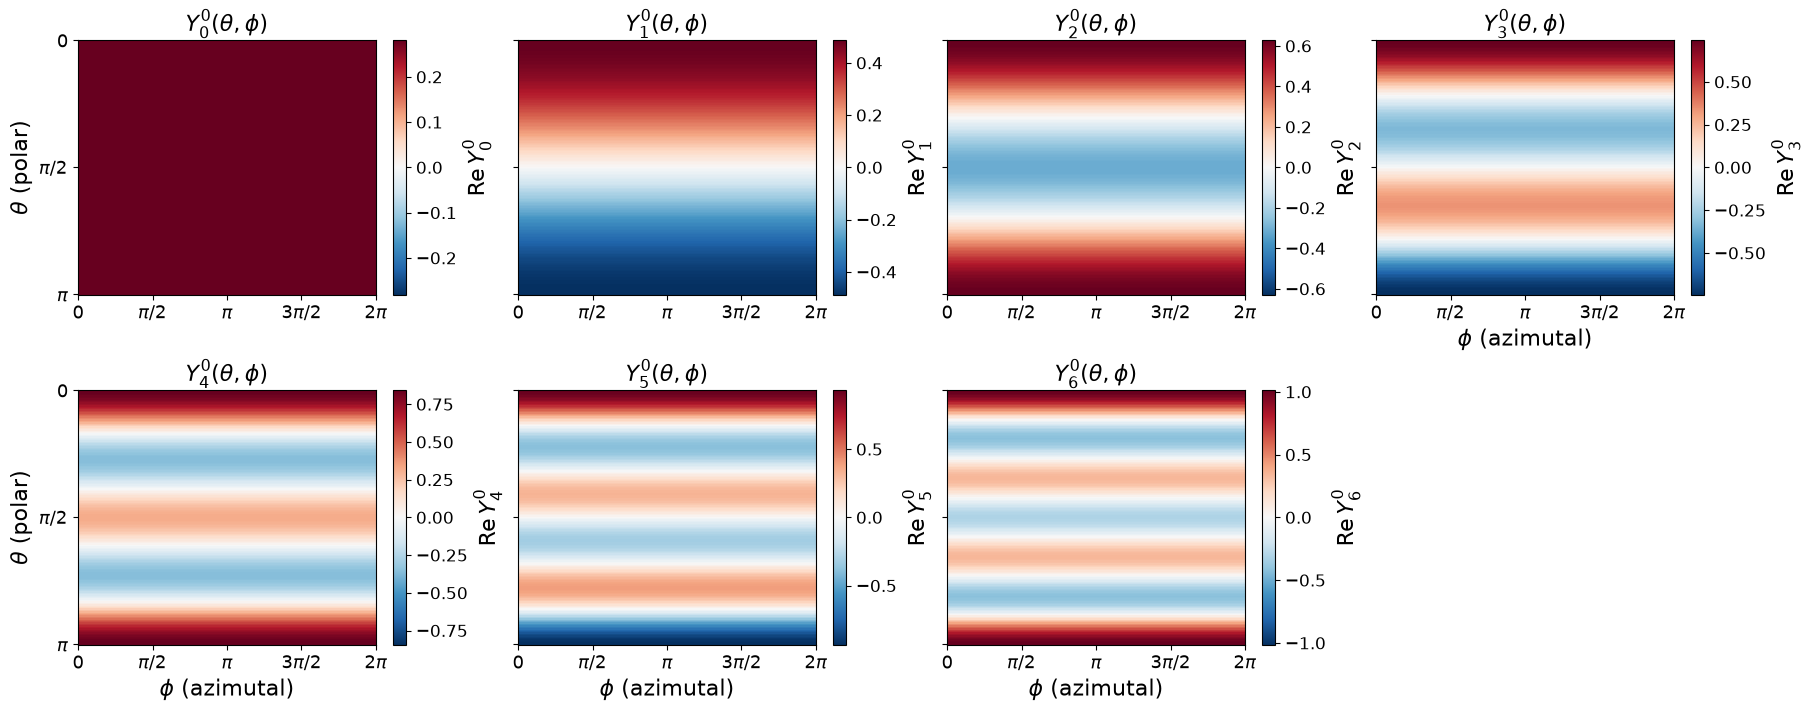

In [49]:
# Modos zonales m = 0, l = 0..6 — mapa (phi, theta) (celda independiente: se puede borrar)
modos0 = [(l, 0) for l in range(7)]
Ys0 = {(l, m): sph_harm_y(l, m, POL, AZ).real for l, m in modos0}

fig, axs = plt.subplots(2, 4, figsize=(18, 7), sharey=True, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos0):
    Y = Ys0[(l, m)]
    vmax = np.abs(Y).max()                     # escala simétrica: blanco = 0
    im = ax.pcolormesh(AZ, POL, Y, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
    cb = fig.colorbar(im, ax=ax, pad=0.02)
    cb.set_label(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=16)
    cb.ax.tick_params(labelsize=12)
    ax.set_title(rf'$Y_{{{l}}}^{{{m}}}(\theta,\phi)$', fontsize=16)
    ax.set_xticks(np.linspace(0, 2*np.pi, 5), ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'], fontsize=13)
    ax.set_yticks(np.linspace(0, np.pi, 3), ['0', r'$\pi/2$', r'$\pi$'], fontsize=13)
axs[0, 0].invert_yaxis()                       # polo norte (θ=0) arriba (sharey: aplica a todos)
for ax in [*axs[1, :3], axs[0, 3]]: ax.set_xlabel(r'$\phi$ (azimutal)', fontsize=16)
for ax in axs[:, 0]: ax.set_ylabel(r'$\theta$ (polar)', fontsize=16)
fig.delaxes(axs.flat[-1])                    # 7 modos en una malla de 8
plt.show()

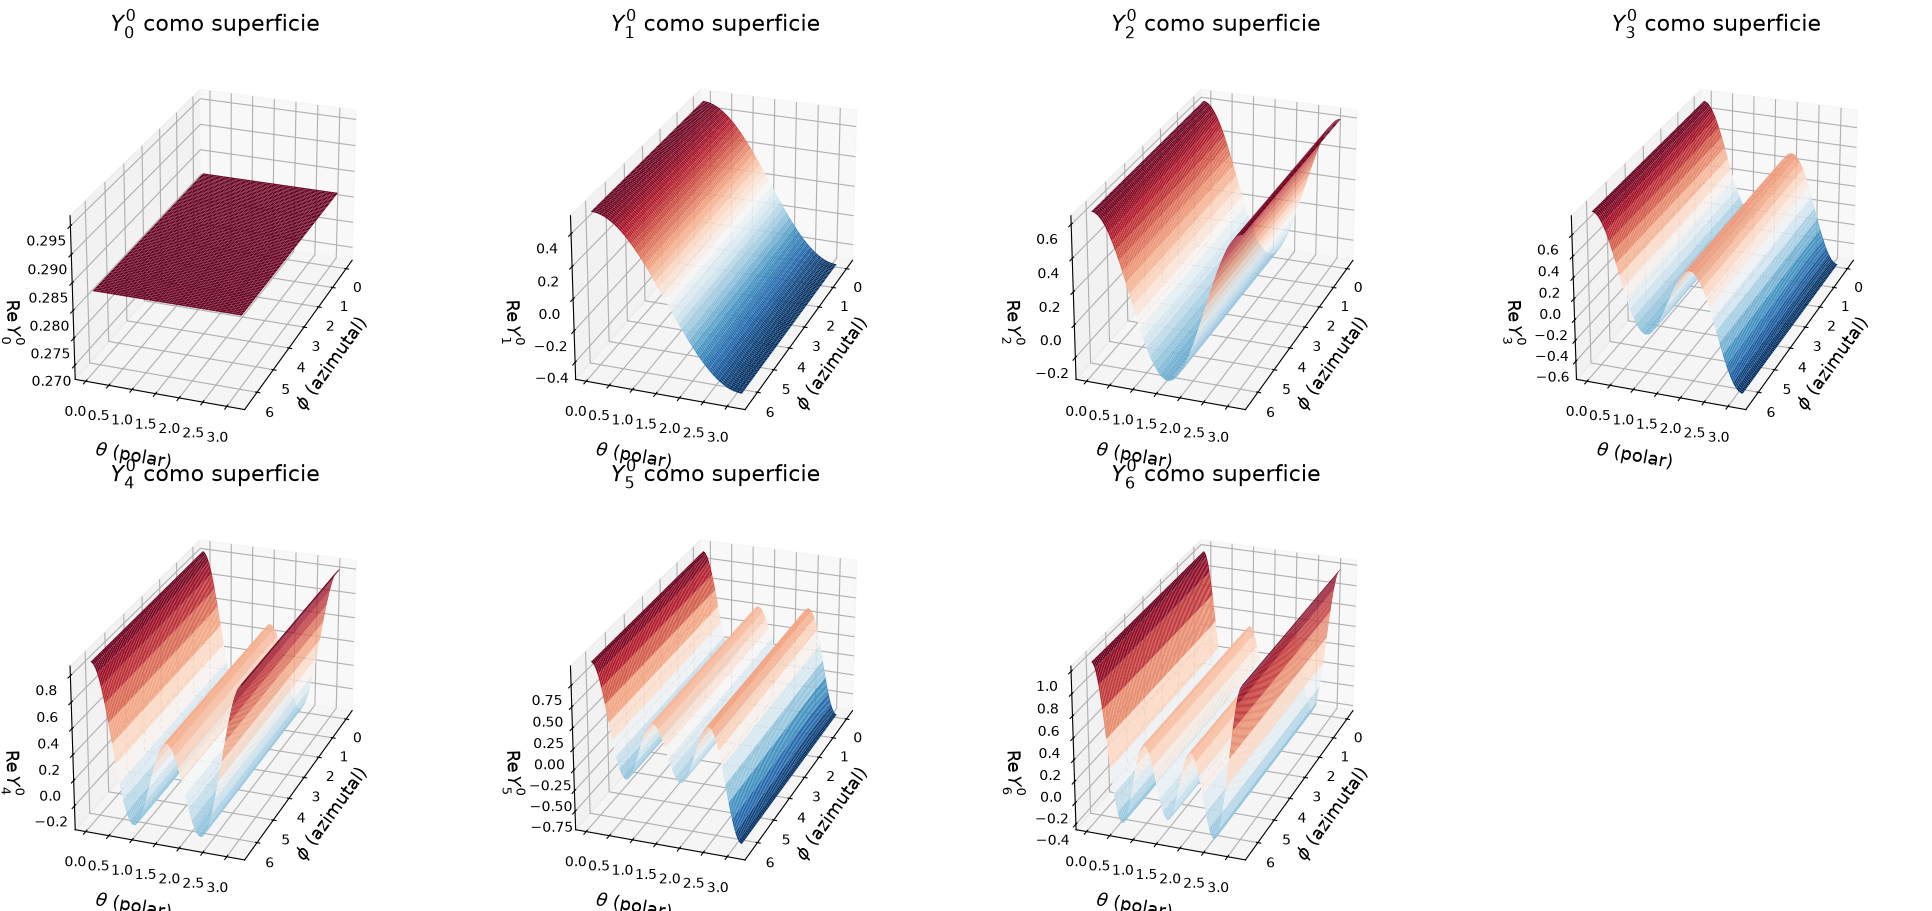

In [50]:
# Modos zonales m = 0, l = 0..6 — superficie 3D (celda independiente: se puede borrar)
modos0 = [(l, 0) for l in range(7)]
Ys0 = {(l, m): sph_harm_y(l, m, POL, AZ).real for l, m in modos0}

fig, axs = plt.subplots(2, 4, figsize=(20, 9), subplot_kw={'projection': '3d'}, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos0):
    Y = Ys0[(l, m)]
    vmax = np.abs(Y).max()
    ax.plot_surface(AZ, POL, Y, cmap='RdBu_r', vmin=-vmax, vmax=vmax, rstride=4, cstride=4, linewidth=0)
    ax.view_init(elev=25, azim=20)             # mira de frente la variación en theta
    ax.set_box_aspect((2, 1, 1))               # phi abarca 2pi, theta abarca pi
    ax.set_xlabel(r'$\phi$ (azimutal)', fontsize=13, labelpad=8)
    ax.set_ylabel(r'$\theta$ (polar)', fontsize=13, labelpad=8)
    ax.set_zlabel(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=13, labelpad=8)
    ax.set_title(rf'$Y_{{{l}}}^{{{m}}}$ como superficie', fontsize=16)
fig.delaxes(axs.flat[-1])                    # 7 modos en una malla de 8
plt.show()

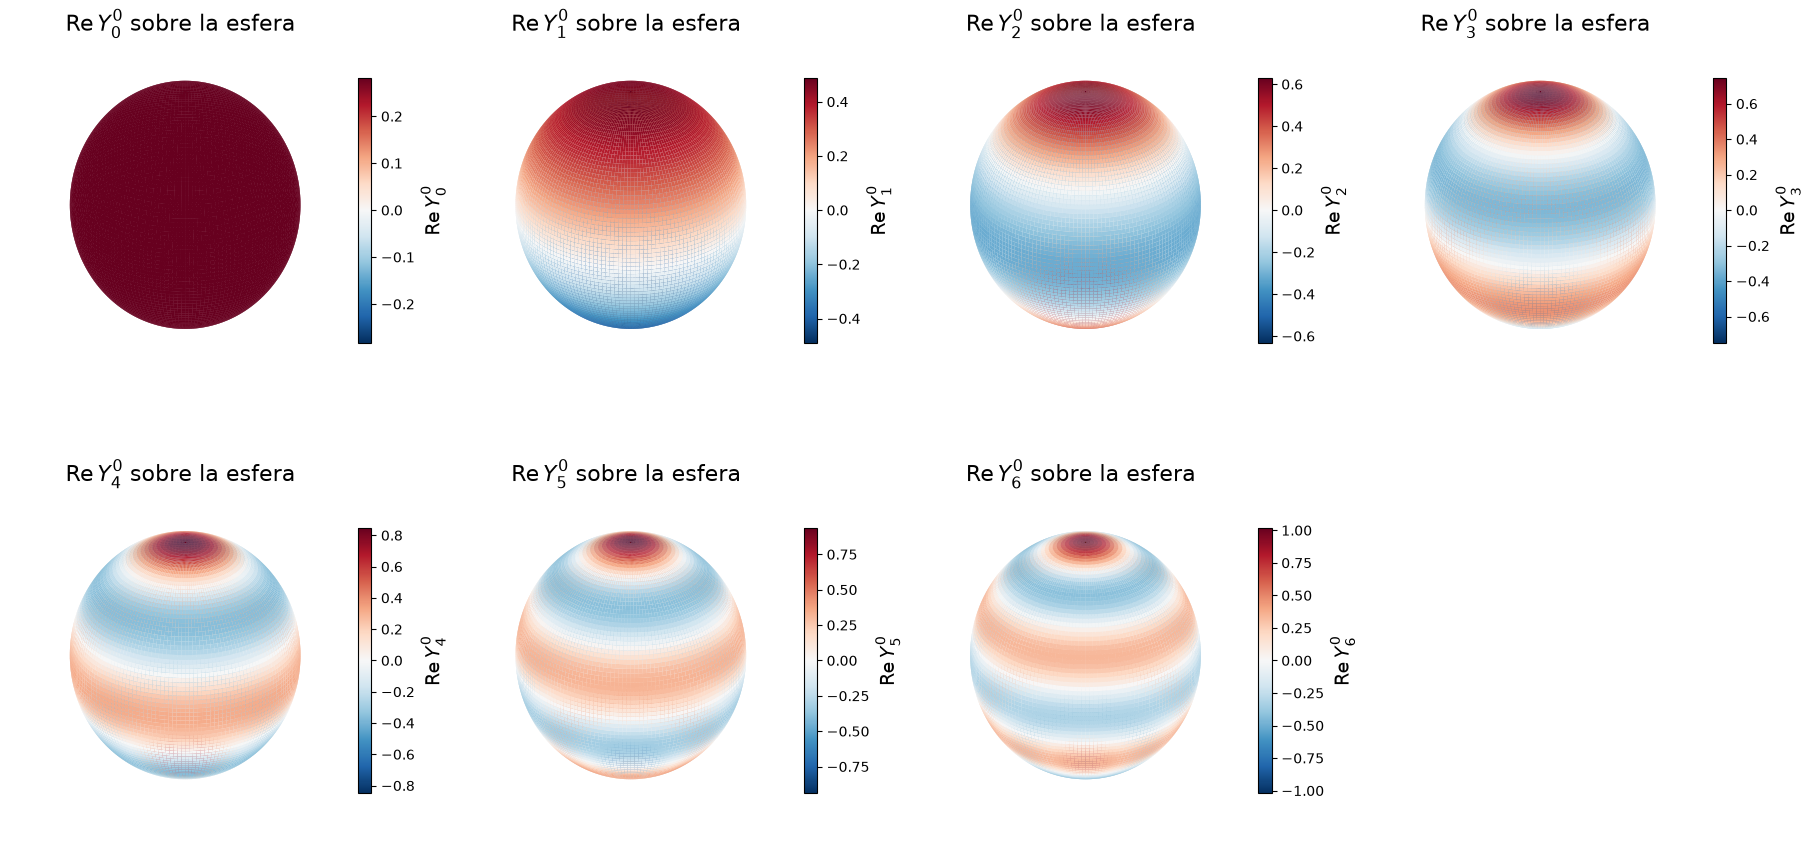

In [51]:
# Modos zonales m = 0, l = 0..6 — sobre la esfera (celda independiente: se puede borrar)
modos0 = [(l, 0) for l in range(7)]
Ys0 = {(l, m): sph_harm_y(l, m, POL, AZ).real for l, m in modos0}

X = np.sin(POL) * np.cos(AZ)
Yc = np.sin(POL) * np.sin(AZ)
Z = np.cos(POL)

fig, axs = plt.subplots(2, 4, figsize=(18, 9), subplot_kw={'projection': '3d'}, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos0):
    Y = Ys0[(l, m)]
    vmax = np.abs(Y).max()
    colores = plt.cm.RdBu_r((Y + vmax) / (2 * vmax))   # mismo mapa de color, 0 en blanco
    ax.plot_surface(X, Yc, Z, facecolors=colores, rstride=2, cstride=2, linewidth=0, shade=False)
    ax.set_box_aspect((1, 1, 1), zoom=1.3)
    ax.set_axis_off()
    ax.set_title(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$ sobre la esfera', fontsize=16)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap='RdBu_r', norm=plt.Normalize(-vmax, vmax)),
                      ax=ax, shrink=0.6, pad=0.02)
    cb.set_label(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=14)
fig.delaxes(axs.flat[-1])                    # 7 modos en una malla de 8
plt.show()

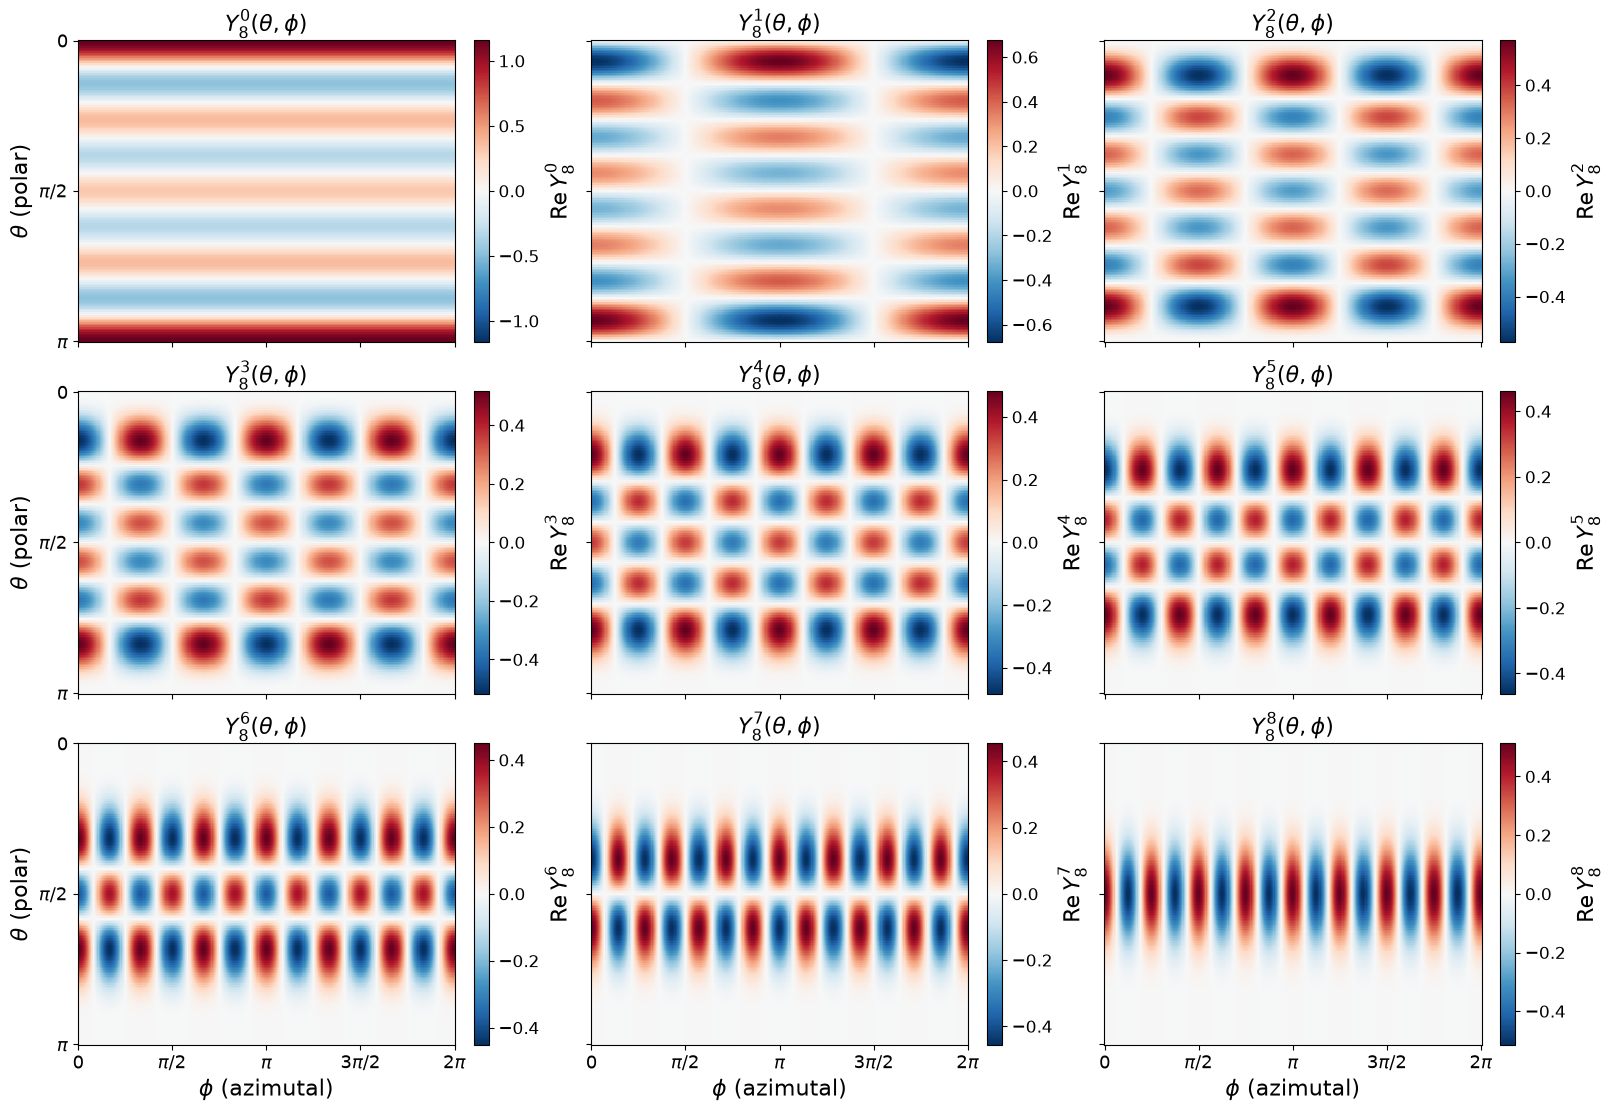

In [55]:
# Modos con l = 8, m = 0..8 — mapa (phi, theta) (celda independiente: se puede borrar)
modos8 = [(8, m) for m in range(9)]
Ys8 = {(l, m): sph_harm_y(l, m, POL, AZ).real for l, m in modos8}

fig, axs = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos8):
    Y = Ys8[(l, m)]
    vmax = np.abs(Y).max()                     # escala simétrica: blanco = 0
    im = ax.pcolormesh(AZ, POL, Y, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='auto')
    cb = fig.colorbar(im, ax=ax, pad=0.02)
    cb.set_label(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=16)
    cb.ax.tick_params(labelsize=12)
    ax.set_title(rf'$Y_{{{l}}}^{{{m}}}(\theta,\phi)$', fontsize=16)
    ax.set_xticks(np.linspace(0, 2*np.pi, 5), ['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'], fontsize=13)
    ax.set_yticks(np.linspace(0, np.pi, 3), ['0', r'$\pi/2$', r'$\pi$'], fontsize=13)
axs[0, 0].invert_yaxis()                       # polo norte (θ=0) arriba (sharey: aplica a todos)
for ax in axs[-1]: ax.set_xlabel(r'$\phi$ (azimutal)', fontsize=16)
for ax in axs[:, 0]: ax.set_ylabel(r'$\theta$ (polar)', fontsize=16)
plt.show()

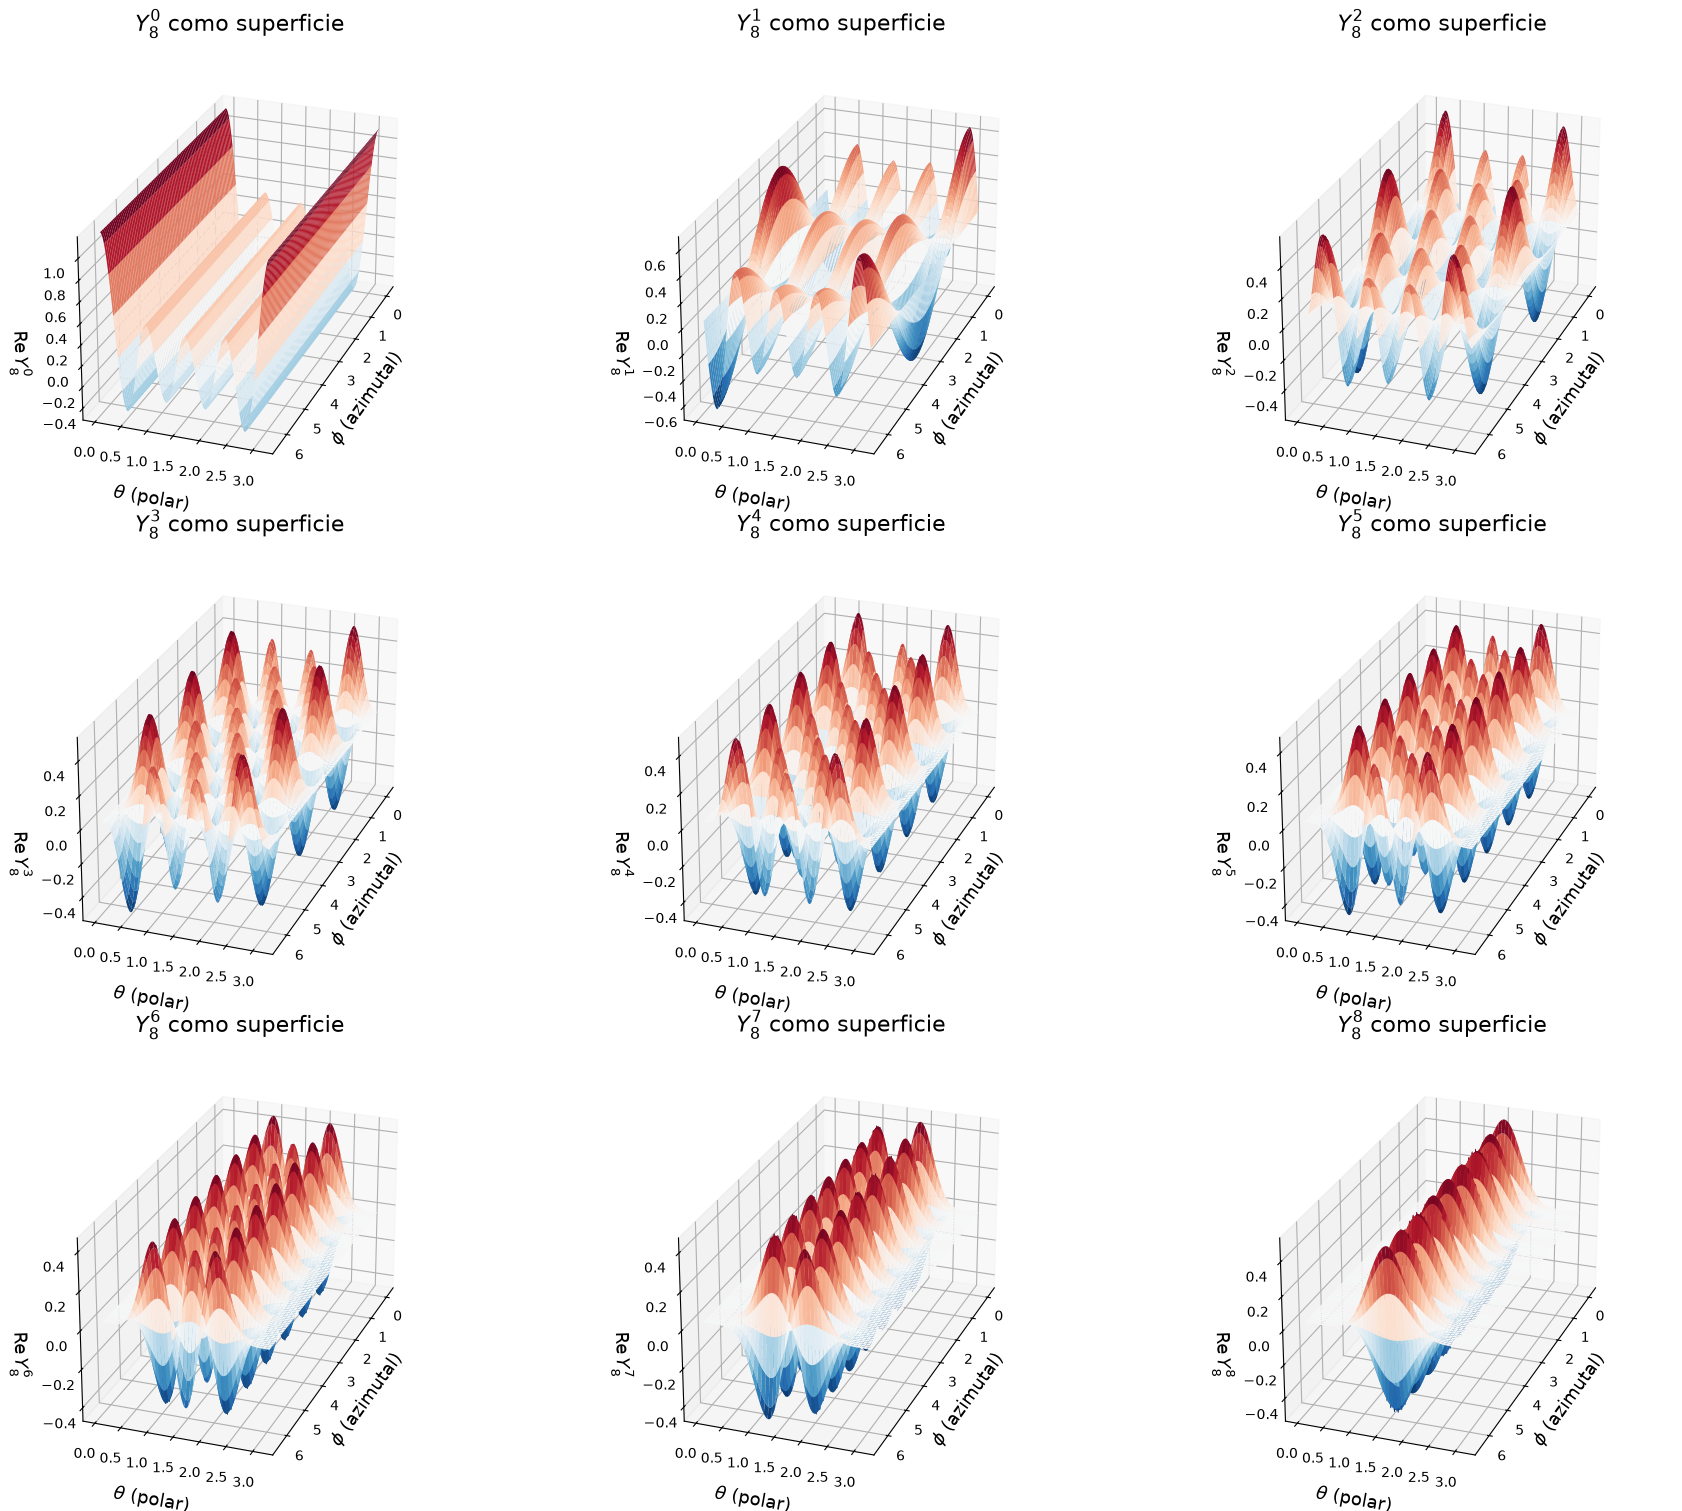

In [56]:
# Modos con l = 8, m = 0..8 — superficie 3D (celda independiente: se puede borrar)
modos8 = [(8, m) for m in range(9)]
Ys8 = {(l, m): sph_harm_y(l, m, POL, AZ).real for l, m in modos8}

fig, axs = plt.subplots(3, 3, figsize=(18, 15), subplot_kw={'projection': '3d'}, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos8):
    Y = Ys8[(l, m)]
    vmax = np.abs(Y).max()
    ax.plot_surface(AZ, POL, Y, cmap='RdBu_r', vmin=-vmax, vmax=vmax, rstride=4, cstride=4, linewidth=0)
    ax.view_init(elev=25, azim=20)             # mira de frente la variación en theta
    ax.set_box_aspect((2, 1, 1))               # phi abarca 2pi, theta abarca pi
    ax.set_xlabel(r'$\phi$ (azimutal)', fontsize=13, labelpad=8)
    ax.set_ylabel(r'$\theta$ (polar)', fontsize=13, labelpad=8)
    ax.set_zlabel(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=13, labelpad=8)
    ax.set_title(rf'$Y_{{{l}}}^{{{m}}}$ como superficie', fontsize=16)
plt.show()

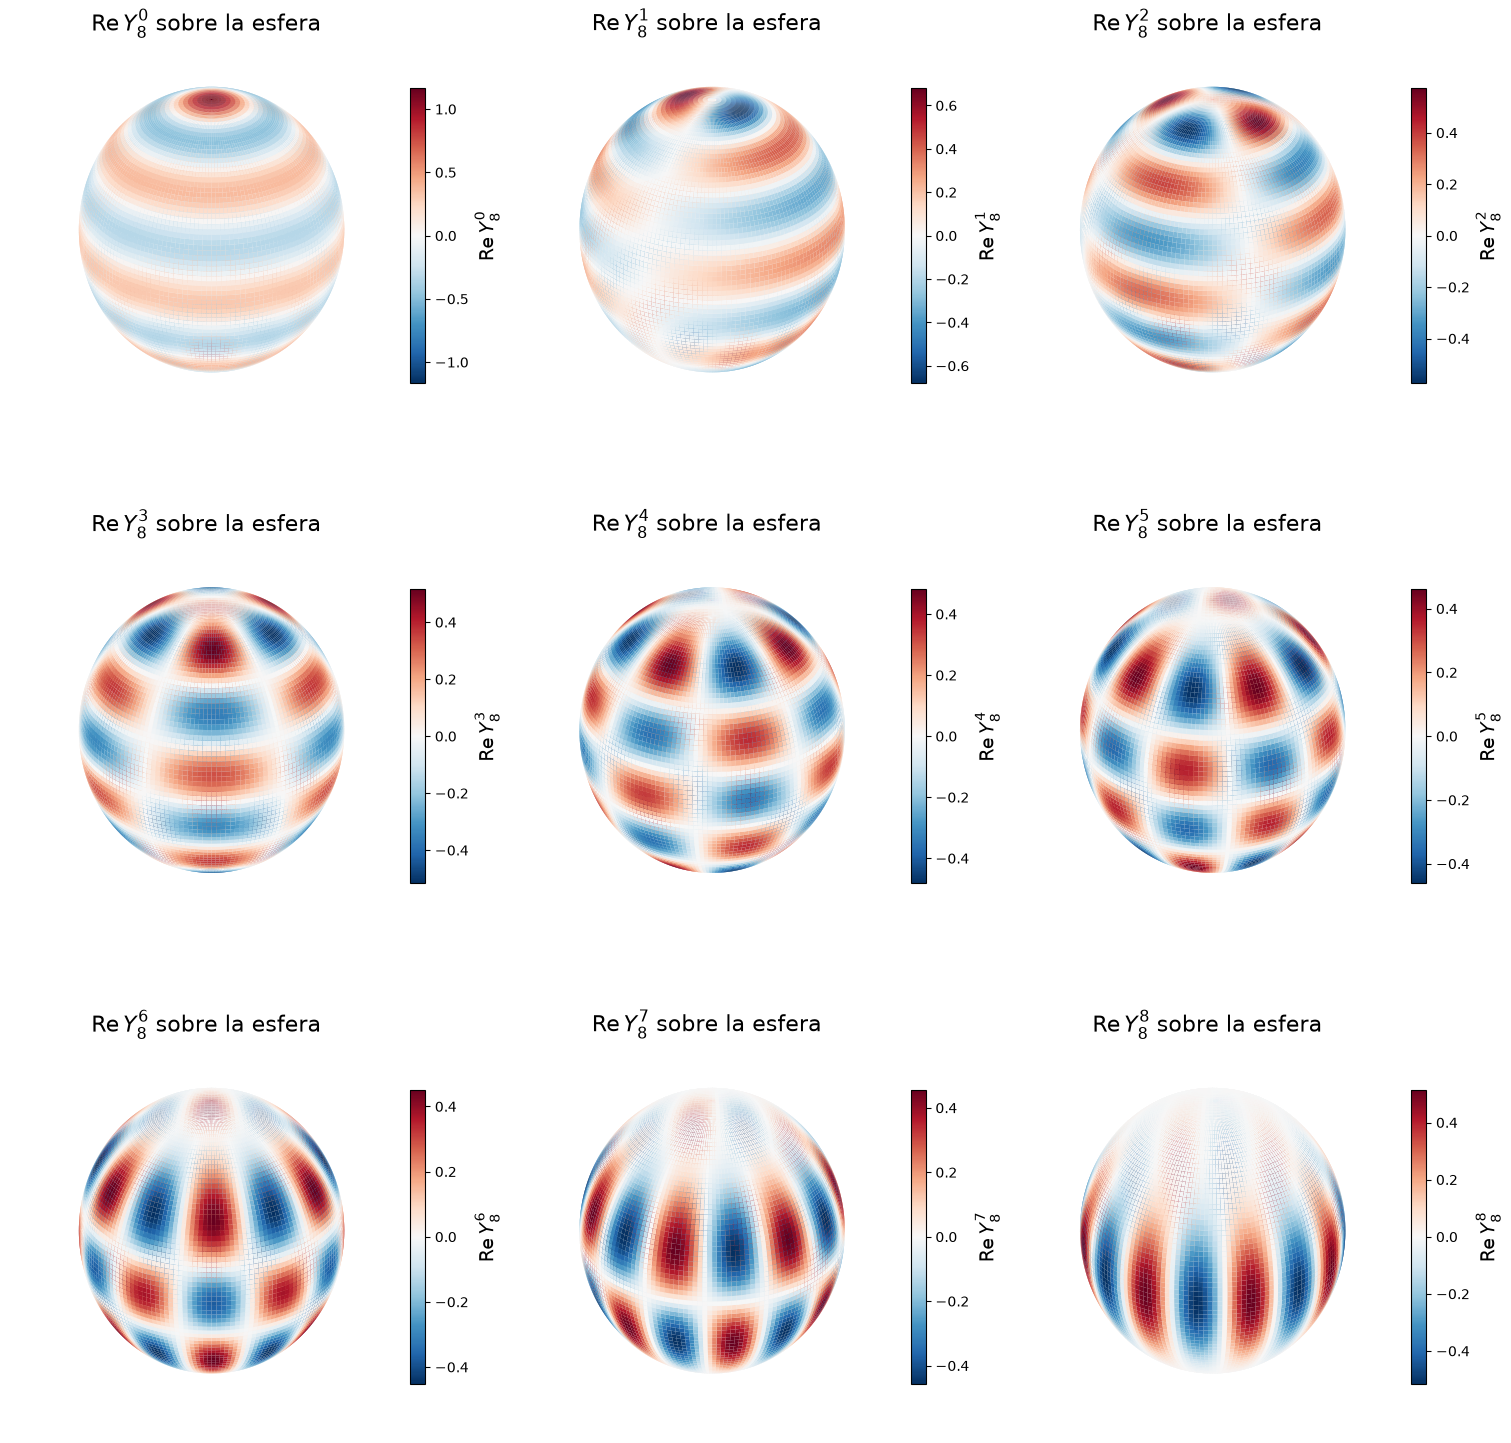

In [57]:
# Modos con l = 8, m = 0..8 — sobre la esfera (celda independiente: se puede borrar)
modos8 = [(8, m) for m in range(9)]
Ys8 = {(l, m): sph_harm_y(l, m, POL, AZ).real for l, m in modos8}

X = np.sin(POL) * np.cos(AZ)
Yc = np.sin(POL) * np.sin(AZ)
Z = np.cos(POL)

fig, axs = plt.subplots(3, 3, figsize=(15, 15), subplot_kw={'projection': '3d'}, constrained_layout=True)
for ax, (l, m) in zip(axs.flat, modos8):
    Y = Ys8[(l, m)]
    vmax = np.abs(Y).max()
    colores = plt.cm.RdBu_r((Y + vmax) / (2 * vmax))   # mismo mapa de color, 0 en blanco
    ax.plot_surface(X, Yc, Z, facecolors=colores, rstride=2, cstride=2, linewidth=0, shade=False)
    ax.set_box_aspect((1, 1, 1), zoom=1.3)
    ax.set_axis_off()
    ax.set_title(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$ sobre la esfera', fontsize=16)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap='RdBu_r', norm=plt.Normalize(-vmax, vmax)),
                      ax=ax, shrink=0.6, pad=0.02)
    cb.set_label(rf'$\mathrm{{Re}}\,Y_{{{l}}}^{{{m}}}$', fontsize=14)
plt.show()

1. Cuando $\ell$ cambia aparecen más franjas horizontales, que representan que el cambio del módulo de $Y_\ell^m$ cambia más seguido en la dirección polar $\theta$.
2. Cuando $m$ cambia aparecen más franjas verticales, que representan que el cambio del módulo de $Y_\ell^m$ cambia más seguido en la dirección azimutal $\phi$, pero también ocurre que los pico se van acumulando en el centro y la amplitud va tendiendo a cero en los polos.
3. Para $\ell = 0$, se tiene una única franja; para $\ell = 1$, dos franjas; para $\ell = 2$, tres franjas, y así sucesivamente. A $\ell = 0, 1, 2,\dots$ yo le asocio, aproximadamente, $\theta \approx \pi / (\ell + 1)$. Esto debido a que, a mayor $\ell$, mayor oscilación en el módulo de $Y_\ell^m$, lo que se traduce a espacio real como mayor resolución a la hora de representar escalas pequeñas del campo.